In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat


In [2]:
CAM_WIDTH = 1600
CAM_HEIGHT = 1300

In [3]:
calib = cv.FileStorage("calibration.ext", cv.FileStorage_READ)
R1, R2, P1, P2, Q, _, _ = cv.stereoRectify(
    calib.getNode("K1").mat(),
    calib.getNode("D1").mat(),
    calib.getNode("K2").mat(),
    calib.getNode("D2").mat(),
    (CAM_HEIGHT, CAM_WIDTH),
    calib.getNode("R").mat(),
    calib.getNode("T").mat(),
    alpha=0,
)

map_lx, map_ly = cv.initUndistortRectifyMap(
    calib.getNode("K1").mat(),
    calib.getNode("D1").mat(),
    R1,
    P1,
    (CAM_WIDTH, CAM_HEIGHT),
    cv.CV_32FC1,
)
map_rx, map_ry = cv.initUndistortRectifyMap(
    calib.getNode("K2").mat(),
    calib.getNode("D2").mat(),
    R2,
    P2,
    (CAM_WIDTH, CAM_HEIGHT),
    cv.CV_32FC1,
)


def rectify(
    left: cv.typing.MatLike, right: cv.typing.MatLike
) -> tuple[cv.typing.MatLike, cv.typing.MatLike]:
    left = cv.remap(left, map_lx, map_ly, cv.INTER_NEAREST)
    right = cv.remap(right, map_rx, map_ry, cv.INTER_NEAREST)
    return left, right

In [4]:
datapath = "/home/filip-kopyt/jetson-data/frames0/"


def load_frames(number: int) -> tuple[cv.typing.MatLike, cv.typing.MatLike]:
    frames = np.fromfile(
        datapath + "frame" + str(number) + ".raw", dtype=np.uint8
    ).reshape((CAM_HEIGHT, CAM_WIDTH * 2))
    frames = cv.Mat(frames)
    left = frames[:, 0:CAM_WIDTH]
    right = frames[:, CAM_WIDTH:]
    # return left, right
    return rectify(left, right)


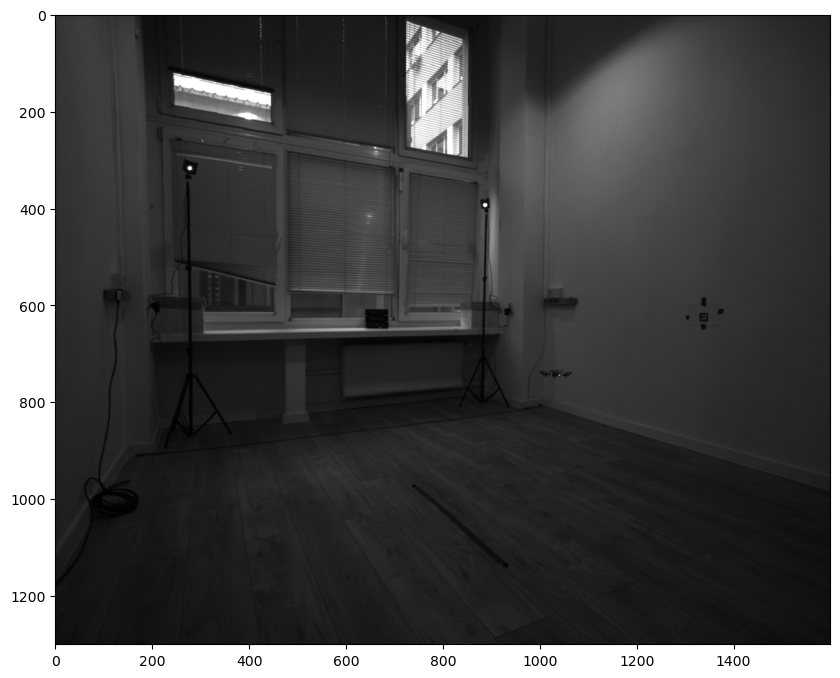

In [5]:
left, right = load_frames(66)
plt.figure(figsize=(10, 10))
plt.imshow(left, cmap="gray")
# cv.imwrite("ex_frame.png", left)
# cv.imwrite("ex_frame2.png", right)

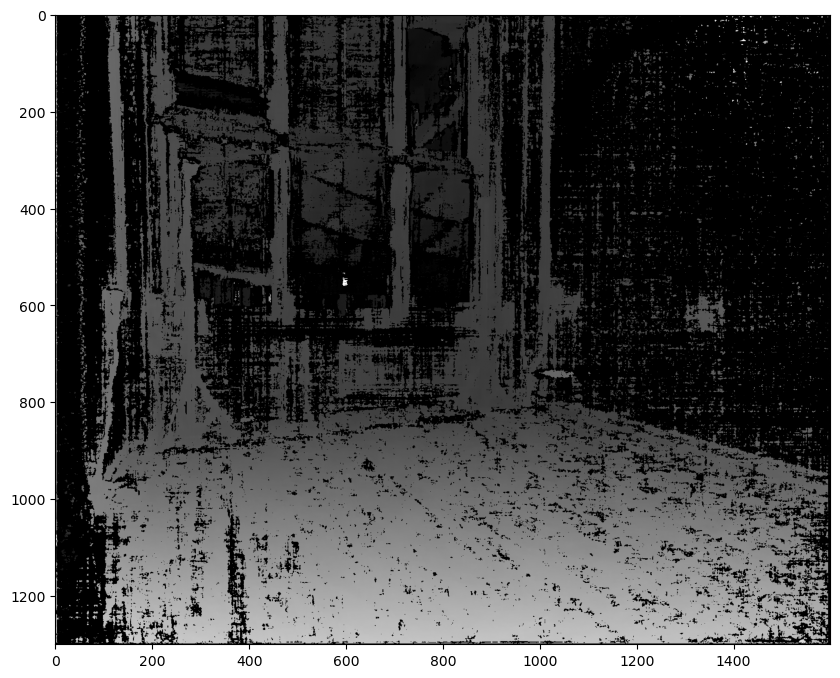

In [6]:
def compute_disparity(left: cv.typing.MatLike, right: cv.typing.MatLike):
    matcher = cv.cuda.createStereoSGM(0, 128, 10, 90, 15, cv.STEREO_SGBM_MODE_HH4)
    left_gpu = cv.cuda.GpuMat(left)
    right_gpu = cv.cuda.GpuMat(right)
    disparity = matcher.compute(left_gpu, right_gpu)  # , cv.cuda.Stream())
    return disparity.download()


disparity = compute_disparity(left, right)
disp_normalized = cv.normalize(disparity, None, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)

plt.figure(figsize=(10, 10))
plt.imshow(disp_normalized, cmap="gray")
# cv.imwrite("bp_pp.png", disp_normalized)

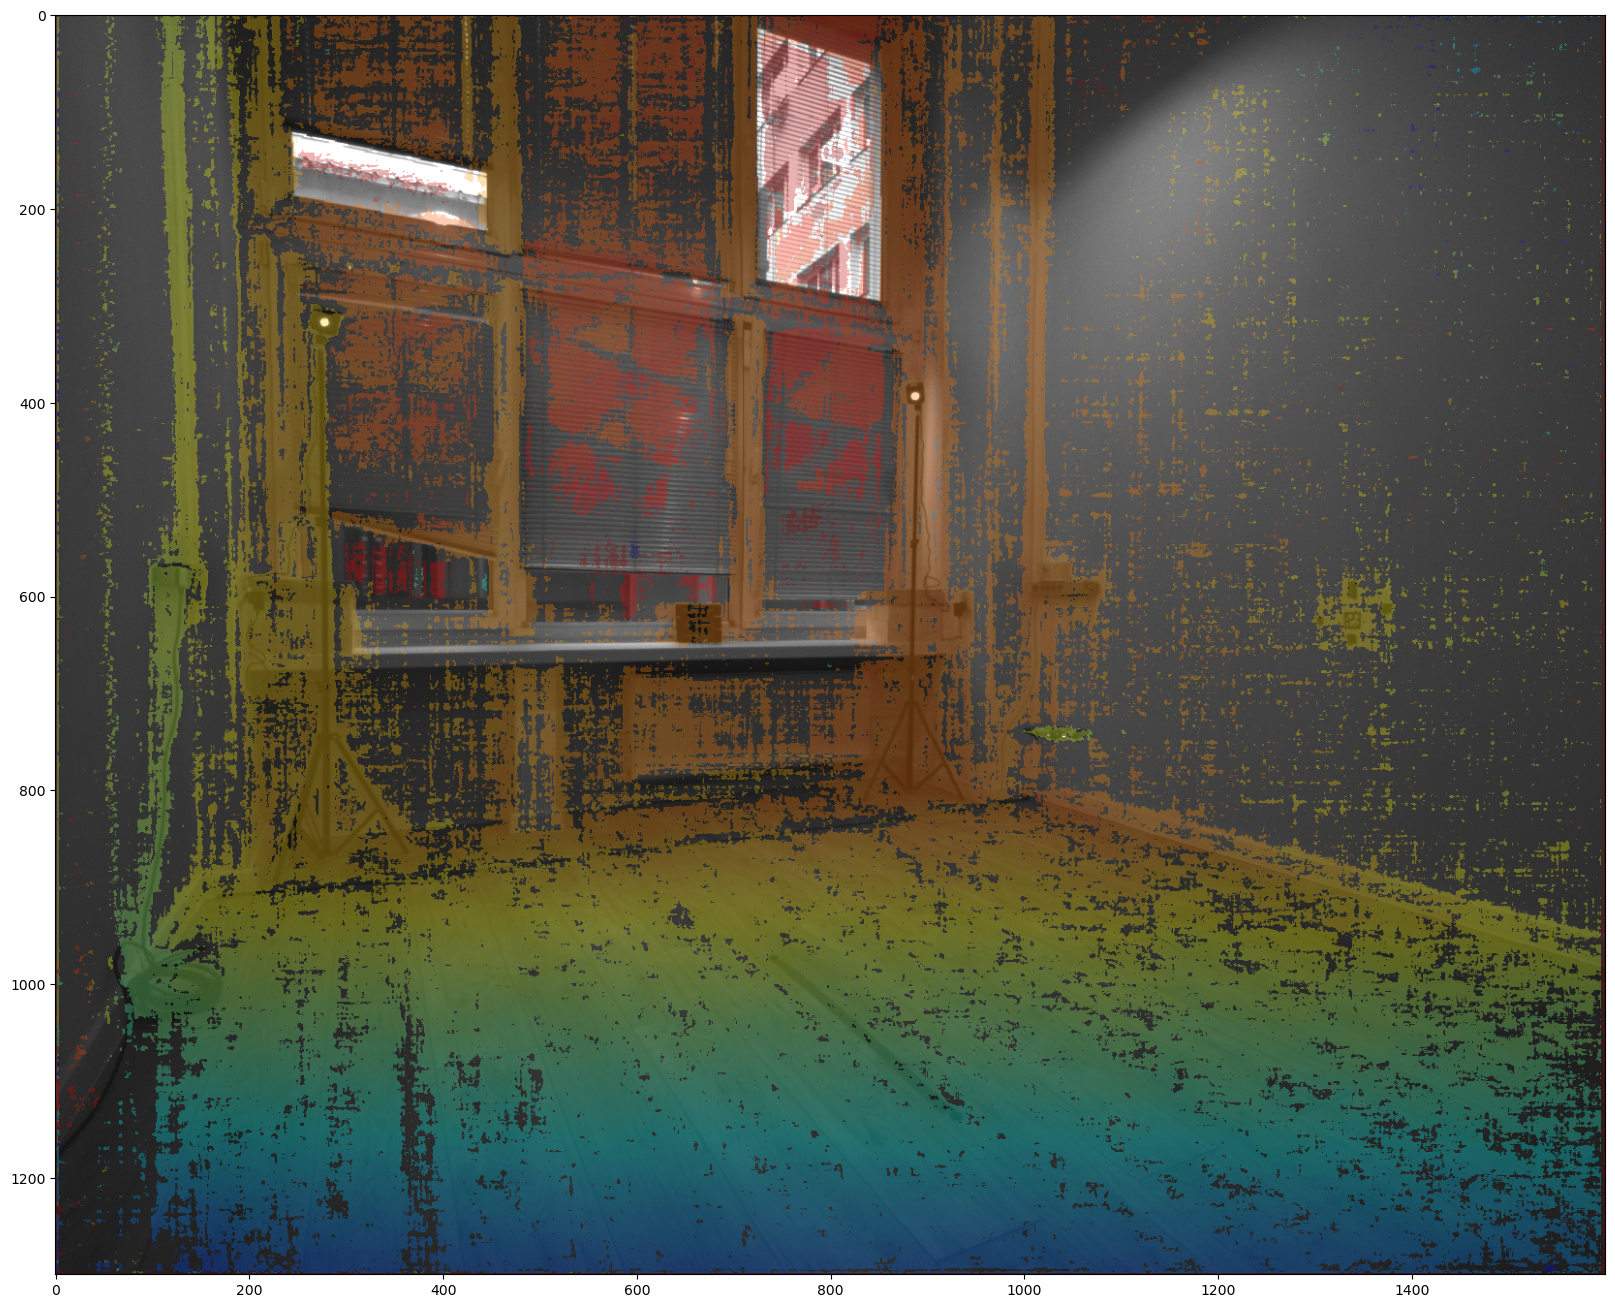

In [7]:
alpha = 0.3

mask = disp_normalized > 0
disp_color = cv.applyColorMap(disp_normalized, cv.COLORMAP_JET)
# disp_color[:, :, 0], disp_color[:, :, 2] = disp_color[:, :, 2], disp_color[:, :, 0]
overlay = left.copy()
# overlay = cv.resize(overlay, None, fx=0.5, fy=0.5, interpolation=cv.INTER_CUBIC)
overlay = cv.cvtColor(overlay, cv.COLOR_GRAY2BGR)

overlay[mask] = cv.addWeighted(overlay[mask], 1 - alpha, disp_color[mask], alpha, 0)

plt.figure(figsize=(20, 20))
plt.imshow(overlay)
# cv.imwrite("frame_n_disp.png", overlay)


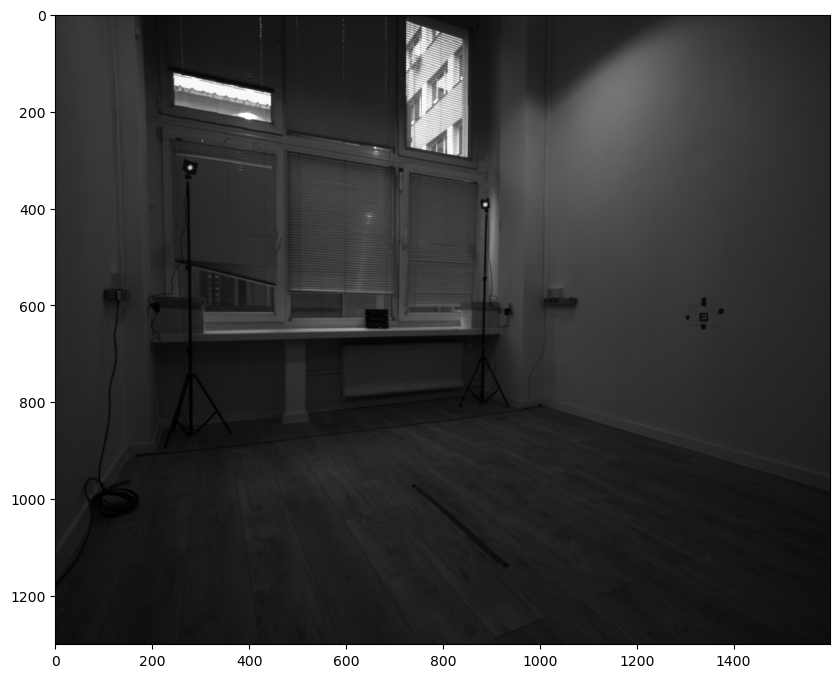

In [8]:
import functools

@functools.cache
def average_frame(n: int = 200):
    framesL = []
    framesR = []
    for i in range(n):
        L, R = load_frames(i)
        framesL.append(L)
        framesR.append(R)
    return np.average(framesL, 0), np.average(framesR, 0)


avg_frame, _ = average_frame()

plt.figure(figsize=(10, 10))
plt.imshow(avg_frame, cmap="gray")

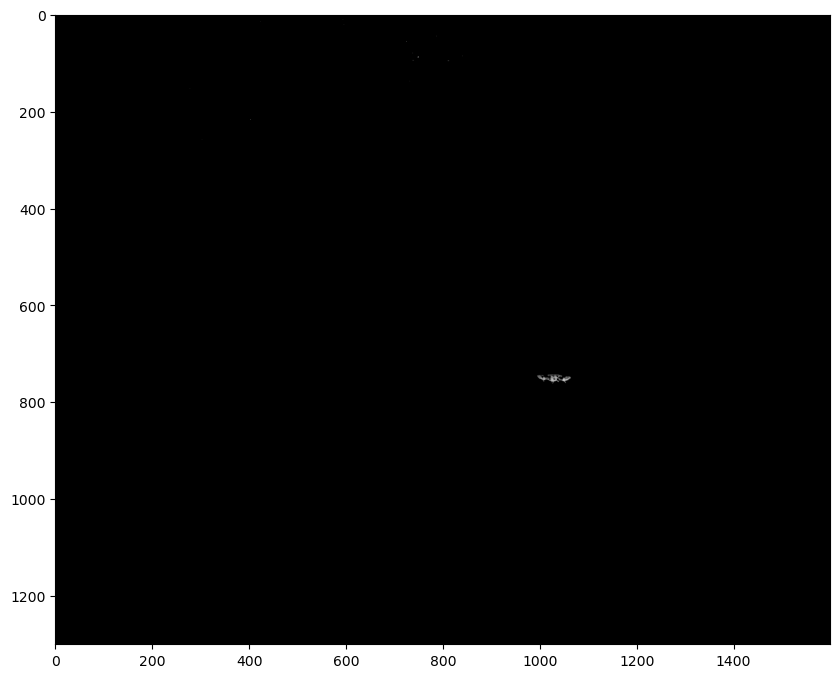

In [9]:
frame, frame2 = load_frames(60)
diff: np.ndarray = avg_frame - frame
# frame = frame[600:900, 800:1200]
diff[diff < 10] = 0
diff[350:450, 850:950] = 0
diff[300:400, 200:300] = 0
# diff = diff[600:900, 800:1200]
# diff = cv.GaussianBlur(diff, (0, 0), 5)
diff = cv.normalize(diff, None, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)
plt.figure(figsize=(10, 10))
plt.imshow(diff, cmap="gray")
# cv.imwrite("diff.png", diff)

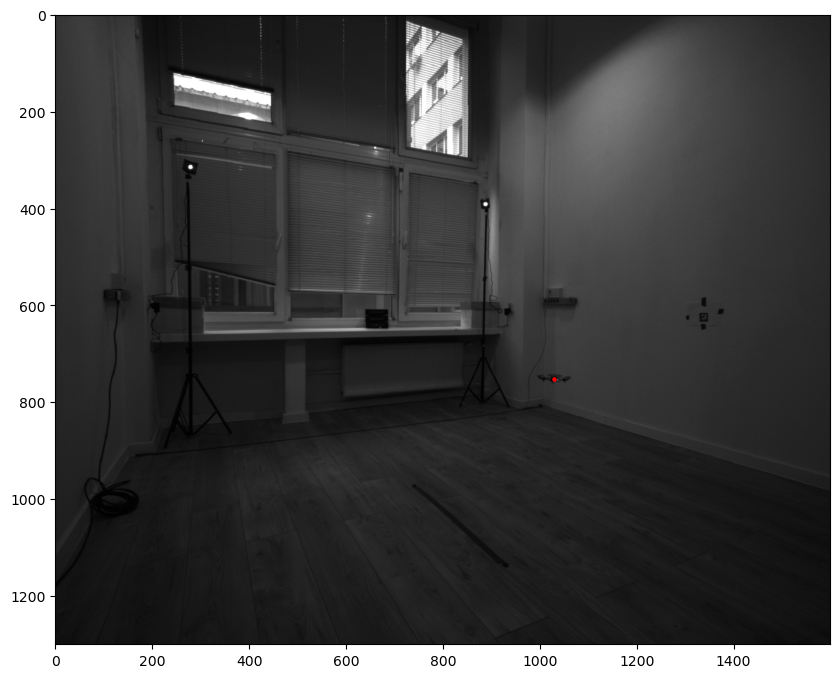

In [10]:
pixels = np.argwhere(diff != 0)
drone_y, drone_x = np.median(pixels, 0)
drone_y = int(drone_y)
drone_x = int(drone_x)

plt.figure(figsize=(10, 10))
plt.imshow(frame, cmap="gray")
plt.scatter(drone_x, drone_y, color="red", s=5)
plt.savefig("point.png")

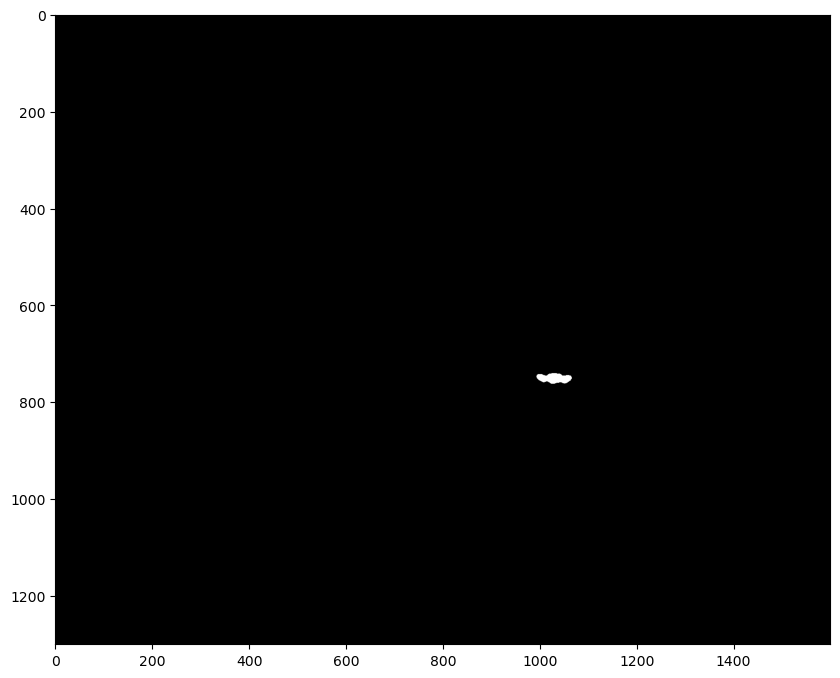

In [11]:
drone_mag_factor = 1.0

drone_patch = diff  # [drone_y-100:drone_y+100, drone_x-100:drone_x+100]
# drone_patch = cv.resize(drone_patch, None, fx=drone_mag_factor, fy=drone_mag_factor, interpolation=cv.INTER_CUBIC)
drone_patch = cv.GaussianBlur(drone_patch, (0, 0), 3)
# drone_patch = drone_patch[(drone_patch.shape[0]//2)-100:(drone_patch.shape[0]//2)+100, (drone_patch.shape[1]//2)-100:(drone_patch.shape[1]//2)+100]
diff_mag = diff.copy()
diff_mag = drone_patch
diff_mag[diff_mag > 15] = 255
diff_mag[diff_mag <= 15] = 0
plt.figure(figsize=(10, 10))
plt.imshow(diff_mag, cmap="gray")
# cv.imwrite('blur1.png', diff_mag)

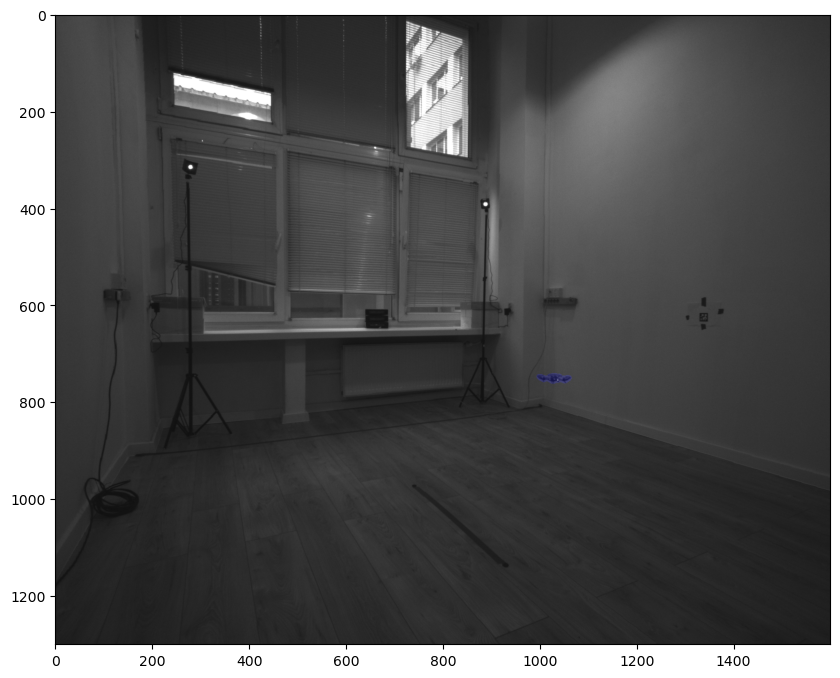

In [12]:
overlay = frame.copy()
overlay = cv.cvtColor(overlay, cv.COLOR_GRAY2BGR)
diff_drone = diff_mag.astype(np.uint8)
diff_drone = cv.cvtColor(diff_drone, cv.COLOR_GRAY2BGR)
diff_drone[:, :, (0, 1)] = 0
overlay = cv.addWeighted(overlay, 1, diff_drone, 0.2, 0)
diff_drone = diff_drone[:, :, 2]

plt.figure(figsize=(10, 10))
plt.imshow(overlay)
# cv.imwrite('drone1.png', overlay)

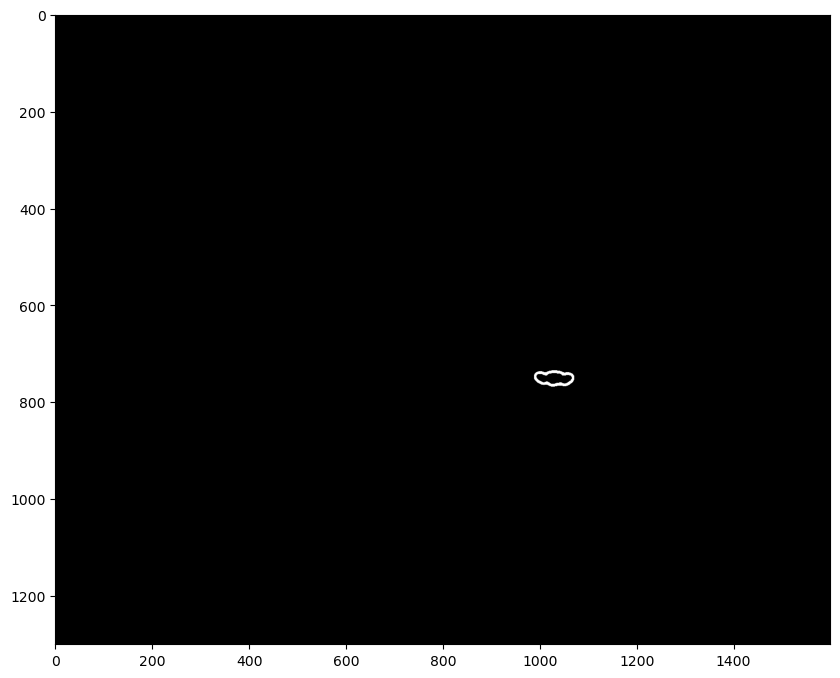

In [13]:
drone_mag_factor = 1

# drone_patch = diff[drone_y-100:drone_y+100, drone_x-100:drone_x+100]
# drone_patch = cv.resize(drone_patch, None, fx=drone_mag_factor, fy=drone_mag_factor, interpolation=cv.INTER_CUBIC)
drone_patch = cv.GaussianBlur(drone_patch, (0, 0), 3)
# drone_patch = drone_patch[(drone_patch.shape[0]//2)-100:(drone_patch.shape[0]//2)+100, (drone_patch.shape[1]//2)-100:(drone_patch.shape[1]//2)+100]
diff_mag = diff.copy()
diff_mag = drone_patch
diff_mag[diff_drone > 5] = 0
diff_mag[diff_mag > 5] = 255
diff_mag[diff_mag <= 5] = 0
plt.figure(figsize=(10, 10))
plt.imshow(diff_mag, cmap="gray")
# cv.imwrite('blur2.png', diff_mag)

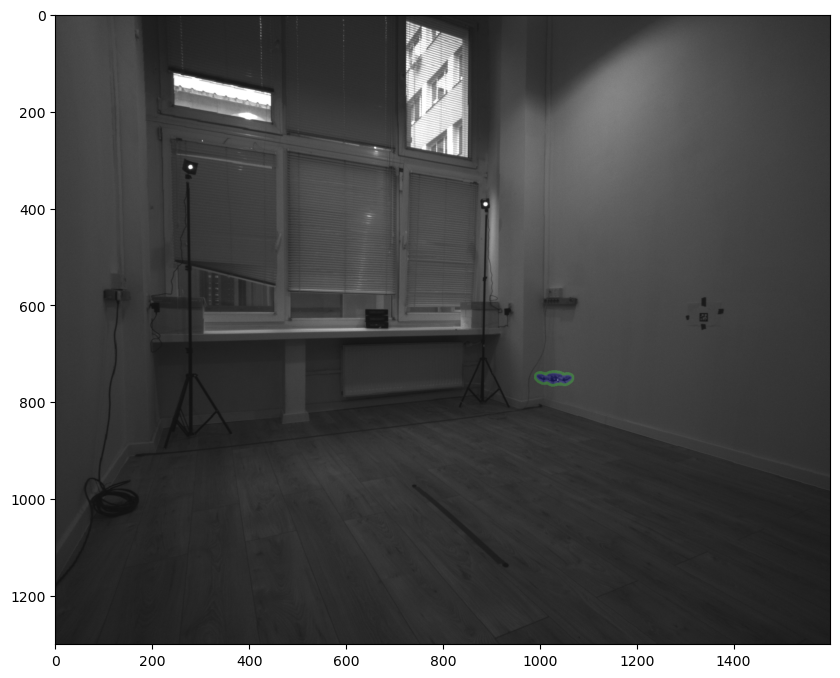

In [14]:
diff_outer = diff_mag.astype(np.uint8)
diff_outer = cv.cvtColor(diff_outer, cv.COLOR_GRAY2BGR)
diff_outer[:, :, (0, 2)] = 0
overlay2 = cv.addWeighted(overlay, 1, diff_outer, 0.2, 0)
diff_outer = diff_outer[:, :, 0]

plt.figure(figsize=(10, 10))
plt.imshow(overlay2)
# cv.imwrite('drone2.png', overlay2)

In [15]:
avgL, avgR = average_frame()
avgL = avgL.astype(np.uint8)
avgR = avgR.astype(np.uint8)

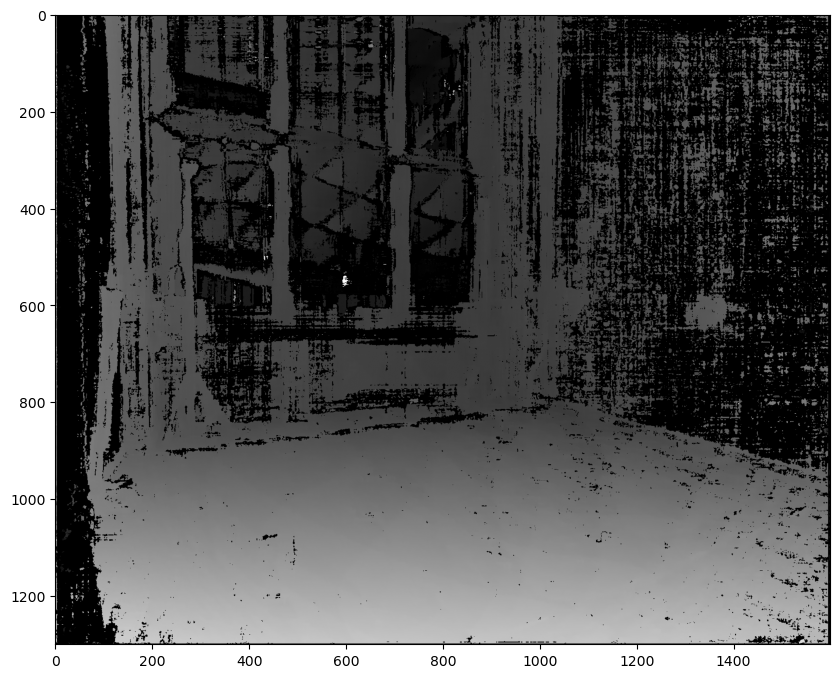

In [16]:
avg_disp = compute_disparity(avgL, avgR)
avg_disp_vis = cv.normalize(avg_disp, None, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)
plt.figure(figsize=(10, 10))
plt.imshow(avg_disp_vis, cmap="gray")

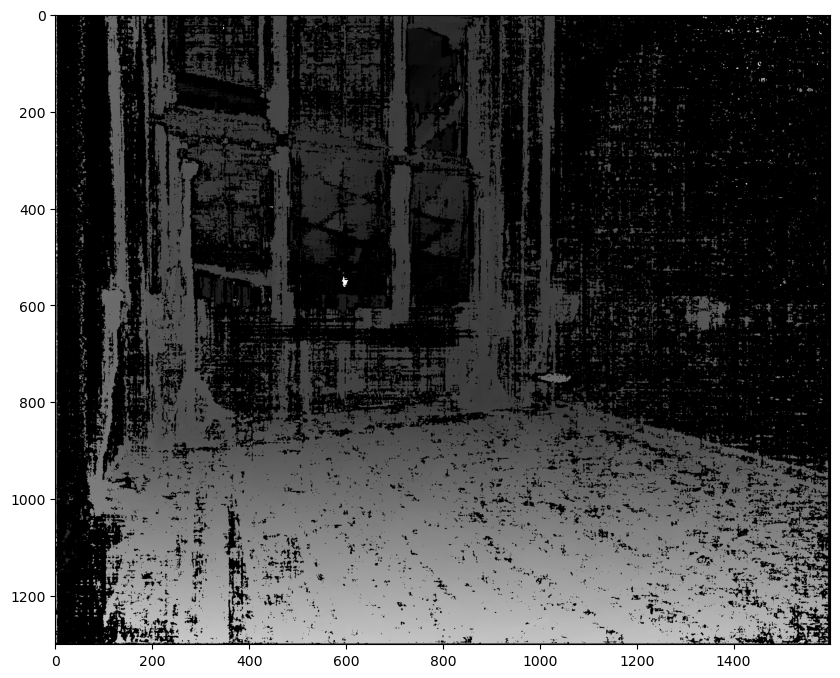

In [17]:
disp = compute_disparity(frame, frame2)
disp_vis = cv.normalize(disp, None, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)
plt.figure(figsize=(10, 10))
plt.imshow(disp_vis, cmap="gray")

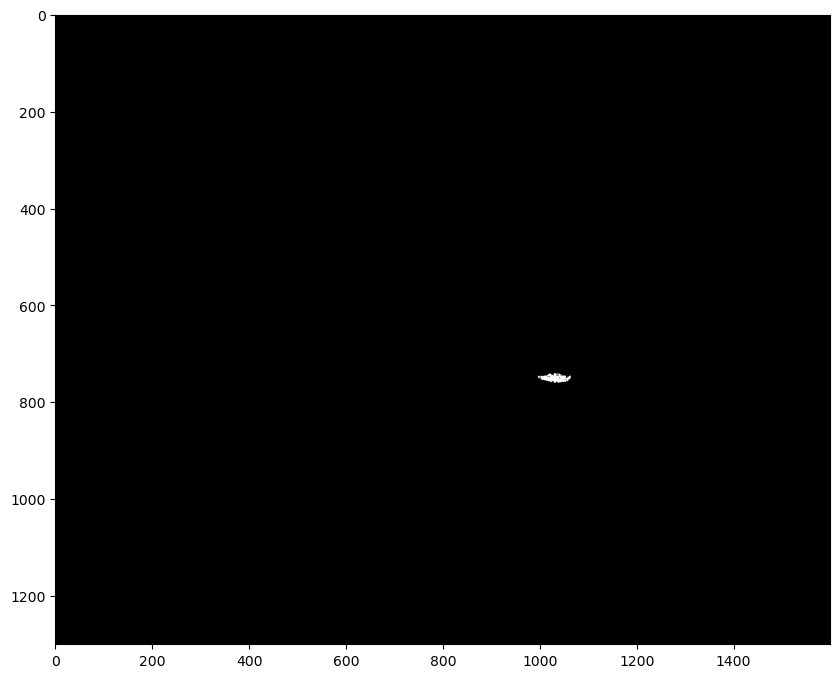

In [18]:
diff = disp - avg_disp
diff[disp <= 0] = 0
diff[diff <= 5] = 0
diff[diff_drone == 0] = 0
diff[diff != 0] = 1
# diff[avg_disp <= 0] = 0

diff_vis = cv.normalize(diff, None, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)

# diff_vis[disp <= 0] = 0
# diff_vis[diff <= 0] = 0
# diff_vis[diff_drone == 0] = 0
# diff_vis[diff != 0] = 255

plt.figure(figsize=(10, 10))
plt.imshow(diff_vis, cmap="gray")

In [19]:
found = np.argwhere(diff != 0).size
total_mask = np.argwhere(diff_drone != 0).size

found / total_mask

0.6909722222222222

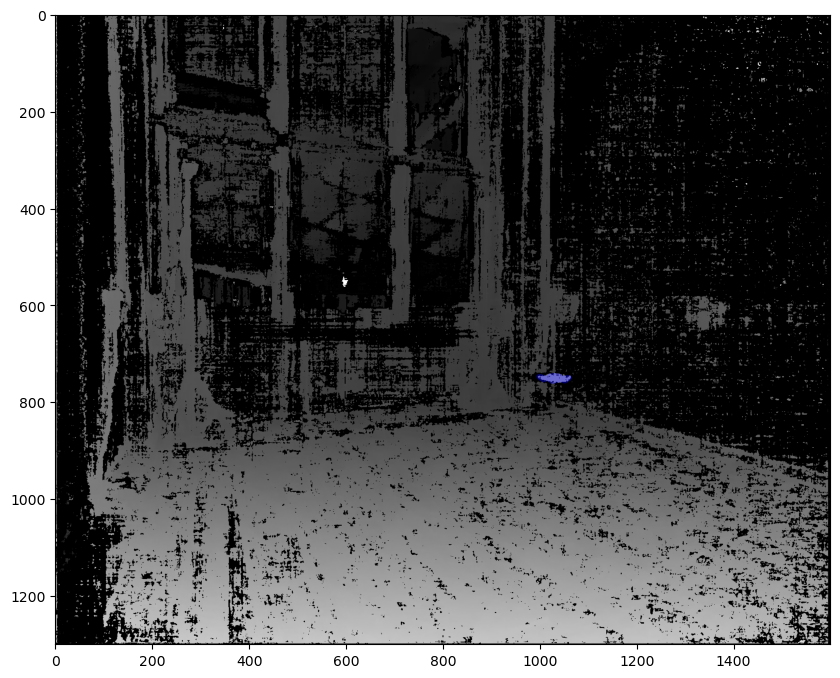

In [20]:
disp_vis = cv.cvtColor(disp_vis, cv.COLOR_GRAY2BGR)
diff_drone = cv.cvtColor(diff_drone, cv.COLOR_GRAY2BGR)
diff_drone[:, :, (0, 1)] = 0

disp_n_drone = cv.addWeighted(disp_vis, 1, diff_drone, 0.4, 0)
plt.figure(figsize=(10, 10))
plt.imshow(disp_n_drone, cmap="gray")

In [21]:
import statistics


type Matcher = cv.cuda.StereoConstantSpaceBP | cv.cuda.StereoBM | cv.cuda.StereoSGM
type Filter = cv.cuda.DisparityBilateralFilter | None

def compute_disparity(
    left: cv.typing.MatLike, right: cv.typing.MatLike, matcher: Matcher, filter: Filter
) -> cv.typing.MatLike:
    gpu_left = cv.cuda.GpuMat(left)
    gpu_right = cv.cuda.GpuMat(right)
    disp: cv.cuda.GpuMat
    match matcher:
        case cv.cuda.StereoSGM():
            disp = matcher.compute(gpu_left, gpu_right)
        case _:
            disp = matcher.compute(gpu_left, gpu_right, cv.cuda.Stream())
    if filter is not None:
        disp = filter.apply(disp, gpu_left)
    return disp.download()


def get_drone_mask(frame: cv.typing.MatLike, avg_frame: cv.typing.MatLike) -> cv.typing.MatLike:
    # average frame have drone blurred out, so the difference is drone + noise
    diff: np.ndarray = avg_frame - frame
    # clear noise
    diff[diff < 15] = 0
    # remove lighthouses blinks
    diff[350:450, 850:950] = 0
    diff[300:400, 200:300] = 0
    # make drone mask larger
    diff = cv.GaussianBlur(diff, (0, 0), 3)
    # make mask binary
    diff[diff > 5] = 255
    diff[diff <= 5] = 0
    diff[diff != 0] = 255
    diff = diff.astype(np.uint8)

    return diff


def score_frame(frame_no: int, matcher: Matcher, filter: Filter) -> tuple[float, int, int]:
    avg_frame, avg_frameR = average_frame()
    left, right = load_frames(frame_no)
    drone_mask = get_drone_mask(left, avg_frame)
    disparity = compute_disparity(left, right, matcher, filter)
    avg_disp = compute_disparity(avg_frame.astype(np.uint8), avg_frameR.astype(np.uint8), matcher, filter)

    diff = disparity - avg_disp

    # no disparity = negitive value, discard diff in this situation
    diff[disparity <= 0] = 0
    # remove values close enough to be classified as either drone or background
    diff[diff <= 5] = 0
    # remove disparity outside the drone mask
    diff[drone_mask == 0] = 0
    # make difference into binary mask
    diff[diff != 0] = 1

    found = np.argwhere(diff != 0).size
    total_mask = np.argwhere(drone_mask != 0).size

    return found / total_mask, found, total_mask


def score(frames: list[int], matcher: Matcher, filter: Filter) -> float:
    return statistics.fmean(score_frame(i, matcher, filter)[0] for i in frames)

In [24]:
import optuna


def objective_sgm_hh4(trial: optuna.Trial):
    ndisp = 128
    min_disp = 0
    p1 = trial.suggest_int("p1", 0, 50)
    p2 = trial.suggest_int("p2", 0, 200)
    uniqueness_ratio = trial.suggest_int("uniqness_ratio", 0, 25)
    use_filter = True

    filter_radius = None
    filter_niter = None

    if use_filter:
        filter_radius = trial.suggest_int("filter_radius", 1, 7)
        filter_niter = trial.suggest_int("filter_niter", 1, 7)

    matcher = cv.cuda.createStereoSGM(min_disp, ndisp, p1, p2, uniqueness_ratio, cv.StereoSGBM_MODE_HH4)
    filter = None

    if use_filter:
        assert filter_radius is not None
        assert filter_niter is not None
        filter = cv.cuda.createDisparityBilateralFilter(ndisp, filter_radius, filter_niter)

    return score(list(range(50, 100)), matcher, filter)

In [37]:
study = optuna.create_study(direction="maximize")
study.optimize(objective_sgm_hh4, n_trials=1000)

[I 2026-11-21 14:26:32,774] A new study created in memory with name: no-name-bd92b6b5-503a-49a3-9e24-037eb89d95db
[I 2026-11-21 14:26:34,341] Trial 0 finished with value: 0.838055500711814 and parameters: {'p1': 37, 'p2': 85, 'uniqness_ratio': 12, 'filter_radius': 1, 'filter_niter': 6}. Best is trial 0 with value: 0.838055500711814.
[I 2026-11-21 14:26:36,009] Trial 1 finished with value: 0.07237884881199837 and parameters: {'p1': 32, 'p2': 167, 'uniqness_ratio': 25, 'filter_radius': 6, 'filter_niter': 4}. Best is trial 0 with value: 0.838055500711814.
[I 2026-11-21 14:26:37,707] Trial 2 finished with value: 0.26887837360650774 and parameters: {'p1': 46, 'p2': 184, 'uniqness_ratio': 18, 'filter_radius': 6, 'filter_niter': 5}. Best is trial 0 with value: 0.838055500711814.
[I 2026-11-21 14:26:39,302] Trial 3 finished with value: 0.5903785760542973 and parameters: {'p1': 38, 'p2': 100, 'uniqness_ratio': 19, 'filter_radius': 7, 'filter_niter': 2}. Best is trial 0 with value: 0.83805550071

In [38]:
def objective_sgm_hh(trial: optuna.Trial):
    ndisp = 128
    min_disp = 0
    p1 = trial.suggest_int("p1", 0, 50)
    p2 = trial.suggest_int("p2", 0, 200)
    uniqueness_ratio = trial.suggest_int("uniqness_ratio", 0, 25)
    use_filter = True

    filter_radius = None
    filter_niter = None

    if use_filter:
        filter_radius = trial.suggest_int("filter_radius", 1, 7)
        filter_niter = trial.suggest_int("filter_niter", 1, 7)

    matcher = cv.cuda.createStereoSGM(min_disp, ndisp, p1, p2, uniqueness_ratio, cv.StereoSGBM_MODE_HH)
    filter = None

    if use_filter:
        assert filter_radius is not None
        assert filter_niter is not None
        filter = cv.cuda.createDisparityBilateralFilter(ndisp, filter_radius, filter_niter)

    return score(list(range(50, 100)), matcher, filter)

In [39]:
study = optuna.create_study(direction="maximize")
study.optimize(objective_sgm_hh, n_trials=1000)

[I 2026-11-21 14:52:19,423] A new study created in memory with name: no-name-38da4aed-c9d4-467b-9e5a-12d347b9fba4


[I 2026-11-21 14:52:21,258] Trial 0 finished with value: 0.5520837494324231 and parameters: {'p1': 31, 'p2': 125, 'uniqness_ratio': 2, 'filter_radius': 1, 'filter_niter': 2}. Best is trial 0 with value: 0.5520837494324231.
[I 2026-11-21 14:52:23,378] Trial 1 finished with value: 0.5526415016110703 and parameters: {'p1': 11, 'p2': 59, 'uniqness_ratio': 10, 'filter_radius': 7, 'filter_niter': 6}. Best is trial 1 with value: 0.5526415016110703.
[I 2026-11-21 14:52:25,237] Trial 2 finished with value: 0.5549417234527246 and parameters: {'p1': 34, 'p2': 182, 'uniqness_ratio': 3, 'filter_radius': 2, 'filter_niter': 3}. Best is trial 2 with value: 0.5549417234527246.
[I 2026-11-21 14:52:27,076] Trial 3 finished with value: 0.6080598203051871 and parameters: {'p1': 40, 'p2': 87, 'uniqness_ratio': 16, 'filter_radius': 6, 'filter_niter': 1}. Best is trial 3 with value: 0.6080598203051871.
[I 2026-11-21 14:52:28,927] Trial 4 finished with value: 0.14612003613515218 and parameters: {'p1': 42, 'p2'

In [52]:
def objective_bm(trial: optuna.Trial):
    ndisp = 128
    block_size = trial.suggest_int("block_size", 3, 19, step=2)
    use_filter = True

    filter_radius = None
    filter_niter = None

    if use_filter:
        filter_radius = trial.suggest_int("filter_radius", 1, 7)
        filter_niter = trial.suggest_int("filter_niter", 1, 7)

    matcher = cv.cuda.createStereoBM(ndisp, block_size)
    filter = None

    if use_filter:
        assert filter_radius is not None
        assert filter_niter is not None
        filter = cv.cuda.createDisparityBilateralFilter(ndisp, filter_radius, filter_niter)

    return score(list(range(50, 100)), matcher, filter)

In [53]:
study = optuna.create_study(direction="maximize")
study.optimize(objective_bm, n_trials=250)

[I 2026-11-21 16:16:15,036] A new study created in memory with name: no-name-698556c8-7dc7-4b61-b6c7-81717d21df52
[I 2026-11-21 16:16:16,930] Trial 0 finished with value: 0.9747621469505698 and parameters: {'block_size': 7, 'filter_radius': 7, 'filter_niter': 2}. Best is trial 0 with value: 0.9747621469505698.
[I 2026-11-21 16:16:18,802] Trial 1 finished with value: 0.9761205943740094 and parameters: {'block_size': 9, 'filter_radius': 4, 'filter_niter': 7}. Best is trial 1 with value: 0.9761205943740094.
[I 2026-11-21 16:16:20,410] Trial 2 finished with value: 0.9482892712321724 and parameters: {'block_size': 3, 'filter_radius': 2, 'filter_niter': 5}. Best is trial 1 with value: 0.9761205943740094.
[I 2026-11-21 16:16:22,023] Trial 3 finished with value: 0.9979800764400208 and parameters: {'block_size': 13, 'filter_radius': 1, 'filter_niter': 2}. Best is trial 3 with value: 0.9979800764400208.
[I 2026-11-21 16:16:23,739] Trial 4 finished with value: 0.991061798332341 and parameters: {'

In [27]:
def objective_bp(trial: optuna.Trial):
    ndisp = 128
    iters = trial.suggest_int("iters", 1, 9)
    levels = trial.suggest_int("levels", 1, 8)
    nr_plane = trial.suggest_int("nr_plane", 1, 9)
    use_filter = True

    filter_radius = None
    filter_niter = None

    if use_filter:
        filter_radius = trial.suggest_int("filter_radius", 1, 5)
        filter_niter = trial.suggest_int("filter_niter", 1, 5)

    matcher = cv.cuda.createStereoConstantSpaceBP(ndisp, iters, levels, nr_plane)
    filter = None

    if use_filter:
        assert filter_radius is not None
        assert filter_niter is not None
        filter = cv.cuda.createDisparityBilateralFilter(ndisp, filter_radius, filter_niter)

    return score(list(range(50, 100)), matcher, filter)

In [28]:
study = optuna.create_study(direction="maximize")
study.optimize(objective_bp, n_trials=500)

[I 2026-11-22 18:51:38,824] A new study created in memory with name: no-name-d55f0766-6622-469d-9fc5-3e39ab048f33


[I 2026-11-22 18:51:50,676] Trial 0 finished with value: 0.8845122424650252 and parameters: {'iters': 9, 'levels': 4, 'nr_plane': 7, 'filter_radius': 3, 'filter_niter': 5}. Best is trial 0 with value: 0.8845122424650252.
[I 2026-11-22 18:52:34,162] Trial 1 finished with value: 0.8970536434622128 and parameters: {'iters': 4, 'levels': 8, 'nr_plane': 8, 'filter_radius': 4, 'filter_niter': 2}. Best is trial 1 with value: 0.8970536434622128.
[I 2026-11-22 18:52:36,768] Trial 2 finished with value: 0.2245423399101519 and parameters: {'iters': 4, 'levels': 1, 'nr_plane': 3, 'filter_radius': 1, 'filter_niter': 4}. Best is trial 1 with value: 0.8970536434622128.
[I 2026-11-22 18:52:39,462] Trial 3 finished with value: 0.9006572447853719 and parameters: {'iters': 6, 'levels': 5, 'nr_plane': 2, 'filter_radius': 3, 'filter_niter': 4}. Best is trial 3 with value: 0.9006572447853719.
[I 2026-11-22 18:52:44,726] Trial 4 finished with value: 0.700159630293918 and parameters: {'iters': 5, 'levels': 2,